# <br><center>**Embed movies by their descriptions**

In [1]:
# integrations
import sys, os, json
from dotenv import load_dotenv; load_dotenv()
print(f"workdir: {os.getcwd()}")

import tmdbsimple as tmdb
import pandas as pd
import numpy as np

from google import genai
print(f"Google GenAI version: {genai.__version__}")

import matplotlib.pyplot as plt
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (30,18),
    "font.size": 14,
    "axes.grid": True,
    "grid.alpha": 0.2
})

workdir: /Users/daniel/creative/projects/movie-clusters
Google GenAI version: 2.33.0


In [3]:
# df = pd.read_csv("./src/data/inspect/top-100-popular.csv.gz", compression="gzip"); df
df = pd.read_csv("./src/data/top-rated.csv.gz", compression="gzip"); df

,id,title,genres,document
0,969681,Spider-Man: Brand New Day,"Science Fiction, Action, Adventure",Title: Spider-Man: Brand New Day (2026). Genre...
1,687163,Project Hail Mary,"Science Fiction, Adventure",Title: Project Hail Mary (2026). Genres: Scien...
2,1003596,Avengers: Doomsday,"Science Fiction, Action, Adventure",Title: Avengers: Doomsday (2026). Genres: Scie...
3,1058424,Hope,"Science Fiction, Mystery, Action","Title: Hope (2026). Genres: Science Fiction, M..."
4,1368337,The Odyssey,"Adventure, Action, Fantasy","Title: The Odyssey (2026). Genres: Adventure, ..."
...,...,...,...,...
1995,1596275,Drive - The Pretenders,"Thriller, Romance",Title: Drive - The Pretenders (2026). Genres: ...
1996,9480,Daredevil,"Fantasy, Action","Title: Daredevil (2003). Genres: Fantasy, Acti..."
1997,949536,Kill Code,"Action, Thriller, Science Fiction","Title: Kill Code (2026). Genres: Action, Thril..."
1998,10661,You Don't Mess with the Zohan,"Comedy, Action",Title: You Don't Mess with the Zohan (2008). G...


In [4]:
print(', '.join(df.title.tolist()))

Spider-Man: Brand New Day, Project Hail Mary, Avengers: Doomsday, Hope, The Odyssey, Street Fighter, Matchbox the Movie, Fall 2: Deadpoint, Insidious: Out of the Further, Masterplan, Other Mommy, Whalefall, Clayface, Animals, The Fix, Resident Evil, Runner, Buddy, Resident Dead, Sacrifice, Practical Magic 2, Digger, You Can See Everything, The Social Reckoning, Don't Move, Toy Story 5, Pinocchio: Unstrung, Dune: Part Three, Sense and Sensibility, The Mongoose, Tenzing, The Nightmare Before Christmas, Disclosure Day, Moana, The Breadwinner, Narnia: The Magician's Nephew, Obsession, War of the Worlds, The End of Oak Street, Don't Leave the Kids Alone, Jailer 2, Resident Evil: Welcome to Raccoon City, Coyote vs. Acme, The Florist, Mutiny, Heart of the Beast, Avengers: Infinity War, Tad and The Magic Lamp, Avengers: Endgame, Love of Your Life, Reporting Live, Minions & Monsters, Don't Look Down, The Weight, Backrooms, Verity, Colony, Bad Apples, Avatar: Fire and Ash, Onslaught, Clue, Inter

In [5]:
# google gemini api
client = genai.Client(api_key=os.getenv("GOOGLE_API_KEY"))

# movie embedding function
def get_movie_embedding(text_content):
    resp = client.models.embed_content(
        model="gemini-embedding-2", contents=text_content
    )
    return resp.embeddings[0].values

# list available embedding models
for model in client.models.list():
    if "embedding" in model.name:
        print(f"Model ID: {model.name}")
        print(f"Supported Operations: {model.supported_actions}\n")

Model ID: models/gemini-embedding-001
Supported Operations: ['embedContent', 'countTextTokens', 'countTokens', 'asyncBatchEmbedContent']

Model ID: models/gemini-embedding-2-preview
Supported Operations: ['embedContent', 'countTextTokens', 'countTokens', 'asyncBatchEmbedContent']

Model ID: models/gemini-embedding-2
Supported Operations: ['embedContent', 'countTextTokens', 'countTokens', 'asyncBatchEmbedContent']



In [6]:
# find mean number of words per document so I get an estimated total tokens i.e., pricing
print(f"Mean document word length: {df["document"].map(lambda doc: len(doc.split())).mean()}")

Mean document word length: 75.0865


In [7]:
# collect really good example movie
movie = df.query("title == 'You Can See Everything'").iloc[0]; movie

id                                                    1765072
title                                  You Can See Everything
genres                                            Documentary
document    Title: You Can See Everything (2026). Genres: ...
Name: 22, dtype: object

In [8]:
# embed example movie
sample_doc = movie["document"]
vector = np.array(get_movie_embedding(sample_doc))
print(f"Movie: {movie["title"]}, Embedding: shape {vector.shape},\n{vector}")

Movie: You Can See Everything, Embedding: shape (3072,),
[ 0.00630858  0.01758288  0.00336293 ... -0.03183414 -0.00636161
 -0.00424083]


In [11]:
# embed multiple movies at once
def get_movie_embeddings(text_contents, batch_size=100):
    all_embeddings = []

    # process chunks
    for i in range(0, len(text_contents), batch_size):
        batch = text_contents[i : i + batch_size]
        contents = [genai.types.Content(parts=[genai.types.Part.from_text(text=t)]) for t in batch]
        resp = client.models.embed_content(
            model="gemini-embedding-2",
            contents=contents
        )
        all_embeddings.extend([e.values for e in resp.embeddings])

    return all_embeddings

In [12]:
# embed all movies in dataset
documents = df.document.tolist()
vectors = np.array(get_movie_embeddings(documents))

In [14]:
embeddings = vectors.copy(); embeddings

array([[ 0.00249047,  0.03379215,  0.00586372, ..., -0.00660918,
        -0.0115659 , -0.00773811],
       [-0.01834785,  0.02906532,  0.01167699, ..., -0.01378255,
        -0.00398634, -0.01577271],
       [-0.01359828,  0.02065756,  0.01488788, ..., -0.00175782,
        -0.00162038, -0.00828521],
       ...,
       [-0.00789588,  0.04249457,  0.00983111, ..., -0.01828845,
         0.00064084, -0.00316996],
       [-0.01248065,  0.0175424 ,  0.02292012, ..., -0.00979056,
        -0.00923521, -0.01824639],
       [-0.00596391,  0.01995538,  0.00823937, ..., -0.02257791,
        -0.02032109,  0.00011146]], shape=(2000, 3072))

In [21]:
# save embeddings
with open("./src/data/embeddings.npy", "wb") as f:
    np.save(f, embeddings)
print("saved embedding vectors!")

saved embedding vectors!


In [22]:
embeddings = np.load("./src/data/embeddings.npy")

In [23]:
# plot movie embeddings
from sklearn.decomposition import PCA
p = PCA(whiten=True, n_components=2, random_state=67)
embeddings_pca = p.fit_transform(embeddings)
print(embeddings_pca.shape)

(2000, 2)


In [24]:
print(f"Explained variance: {p.explained_variance_ratio_.sum()*100:.2f}%")

Explained variance: 7.68%


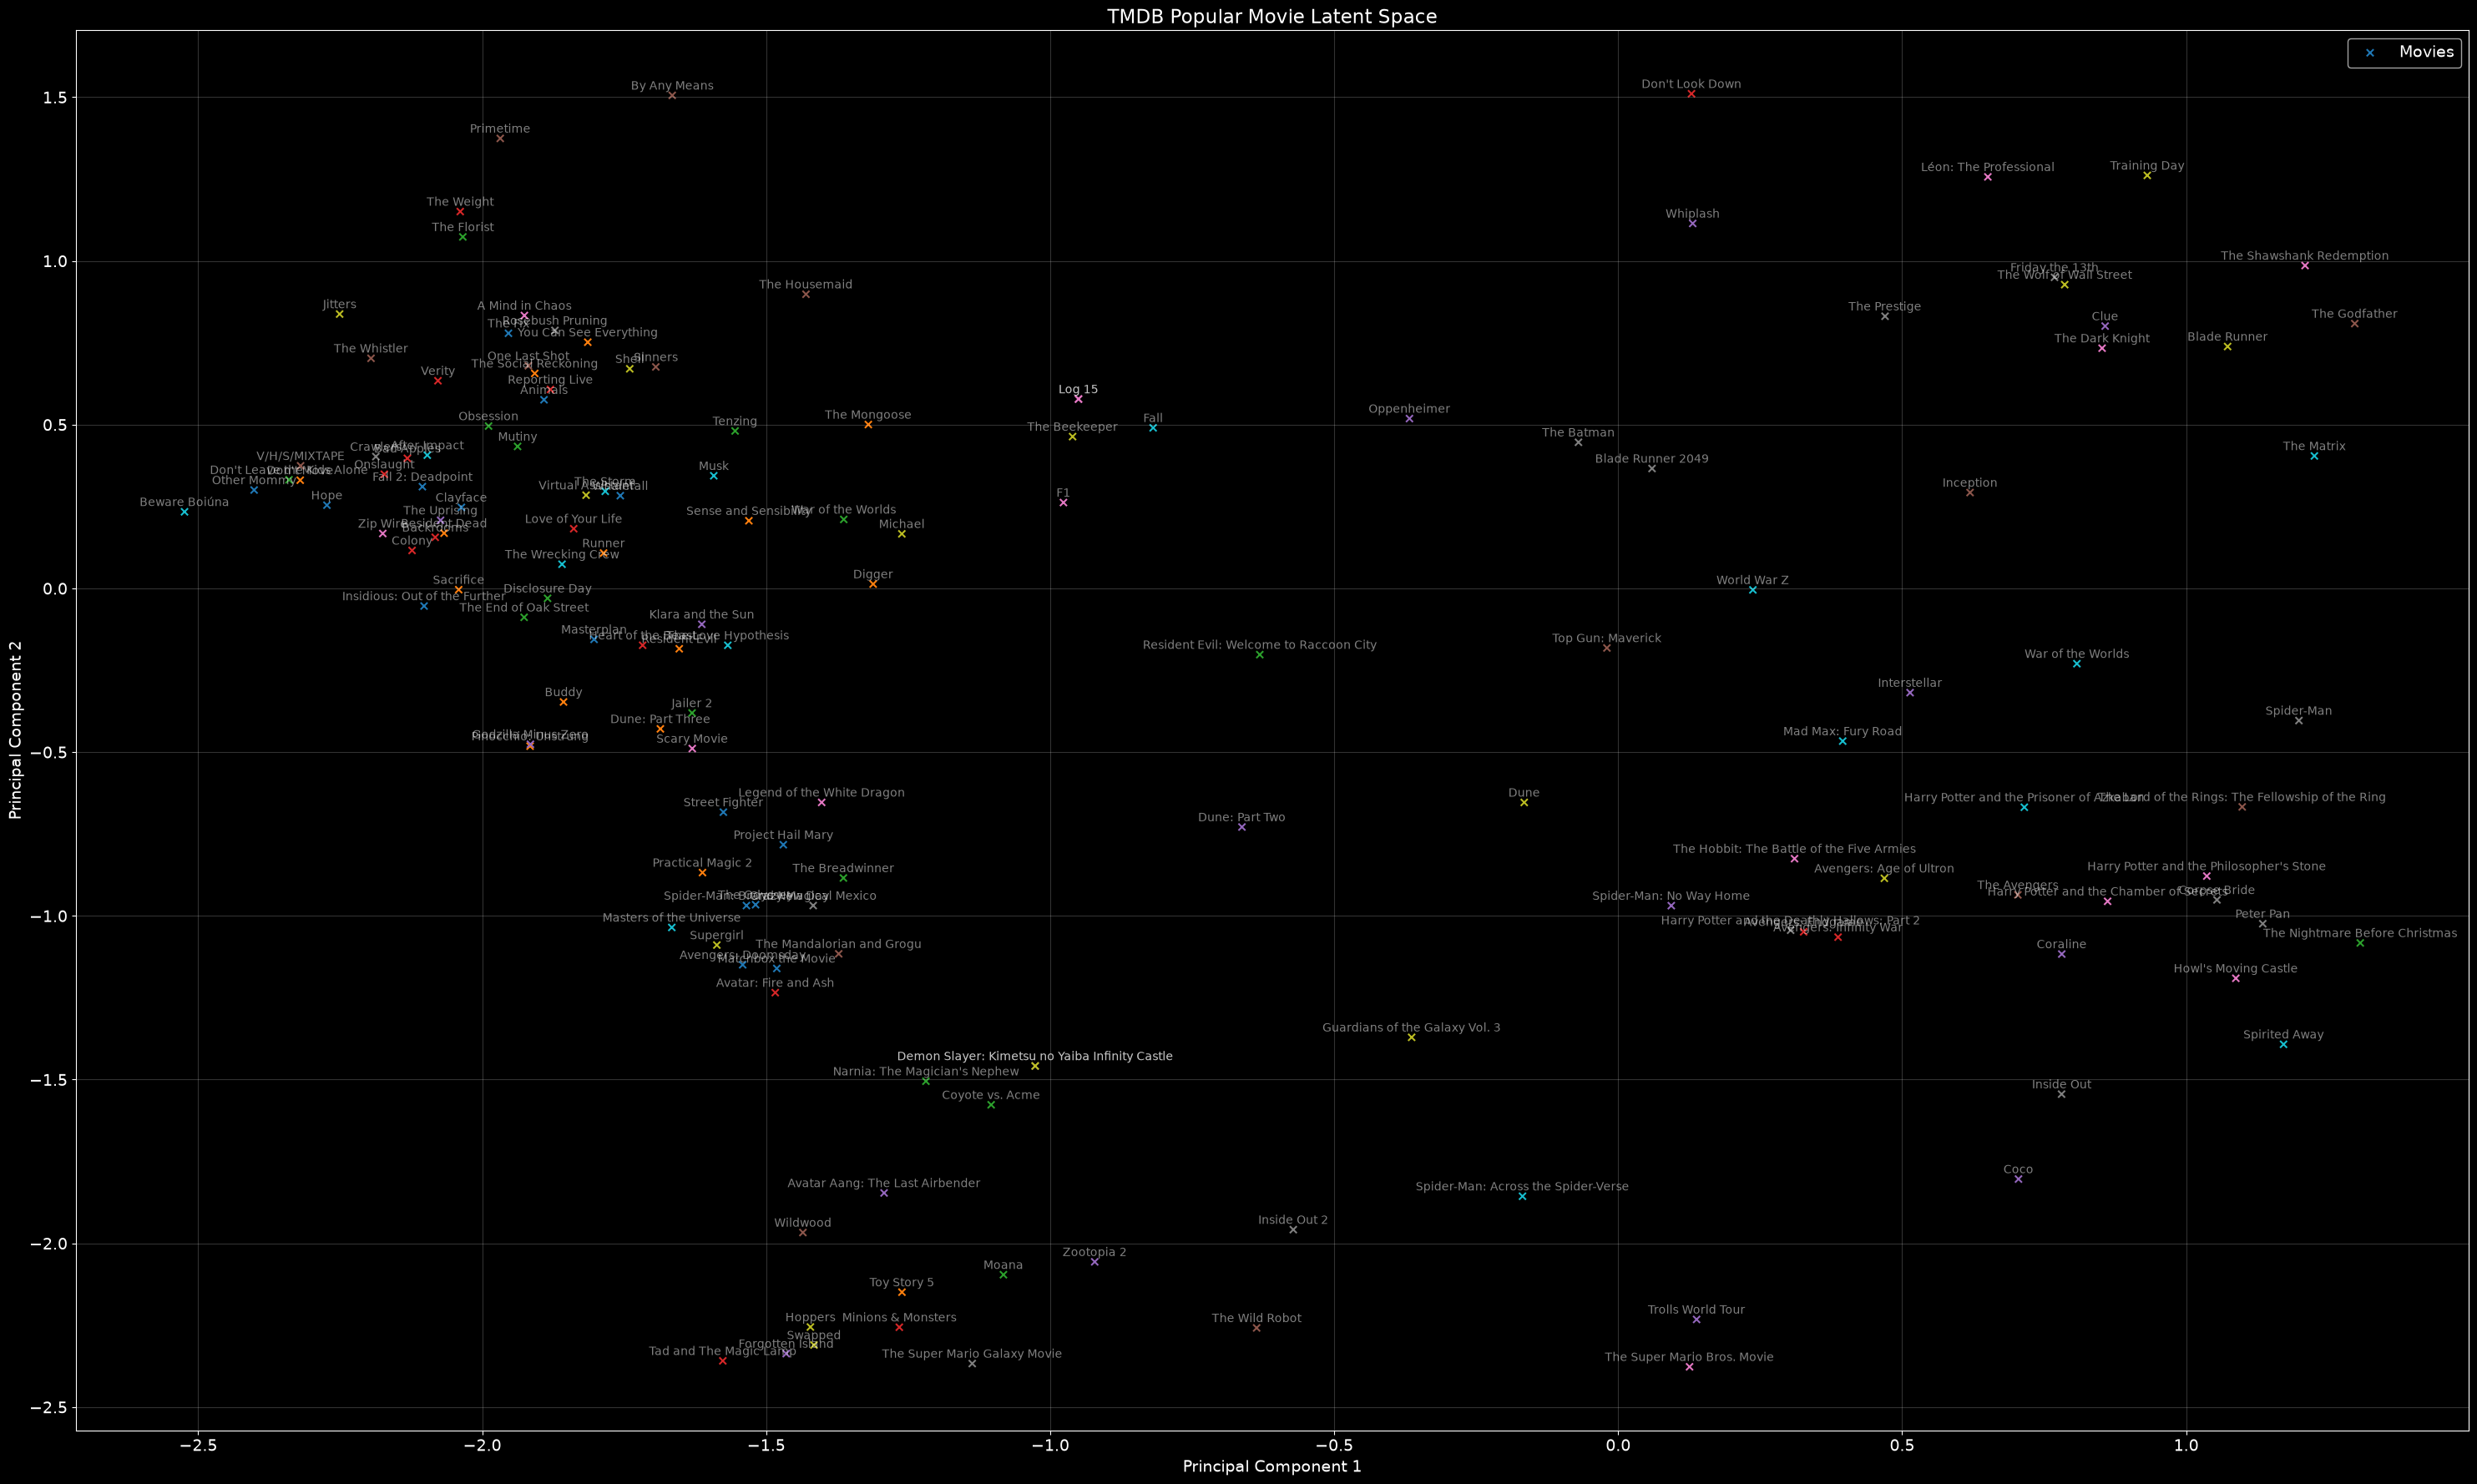

In [32]:
# scatterplot
n_plot = 150
pc1 = embeddings_pca[:,0][:n_plot]
pc2 = embeddings_pca[:,1][:n_plot]

# scatter projected embeddings
plt.scatter(pc1, pc2, marker="x", label="Movies", cmap="tab10", c=np.arange(n_plot))

# add movie titles
for x, y, title in zip(pc1, pc2, df.title.tolist()):
    plt.annotate(title, (x,y), textcoords="offset points", xytext=(0,5), ha="center", fontsize=10, alpha=0.5)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("TMDB Popular Movie Latent Space")
plt.legend()
plt.tight_layout()
plt.savefig("./src/imgs/popular-movie-latent-space.jpg")
plt.show()

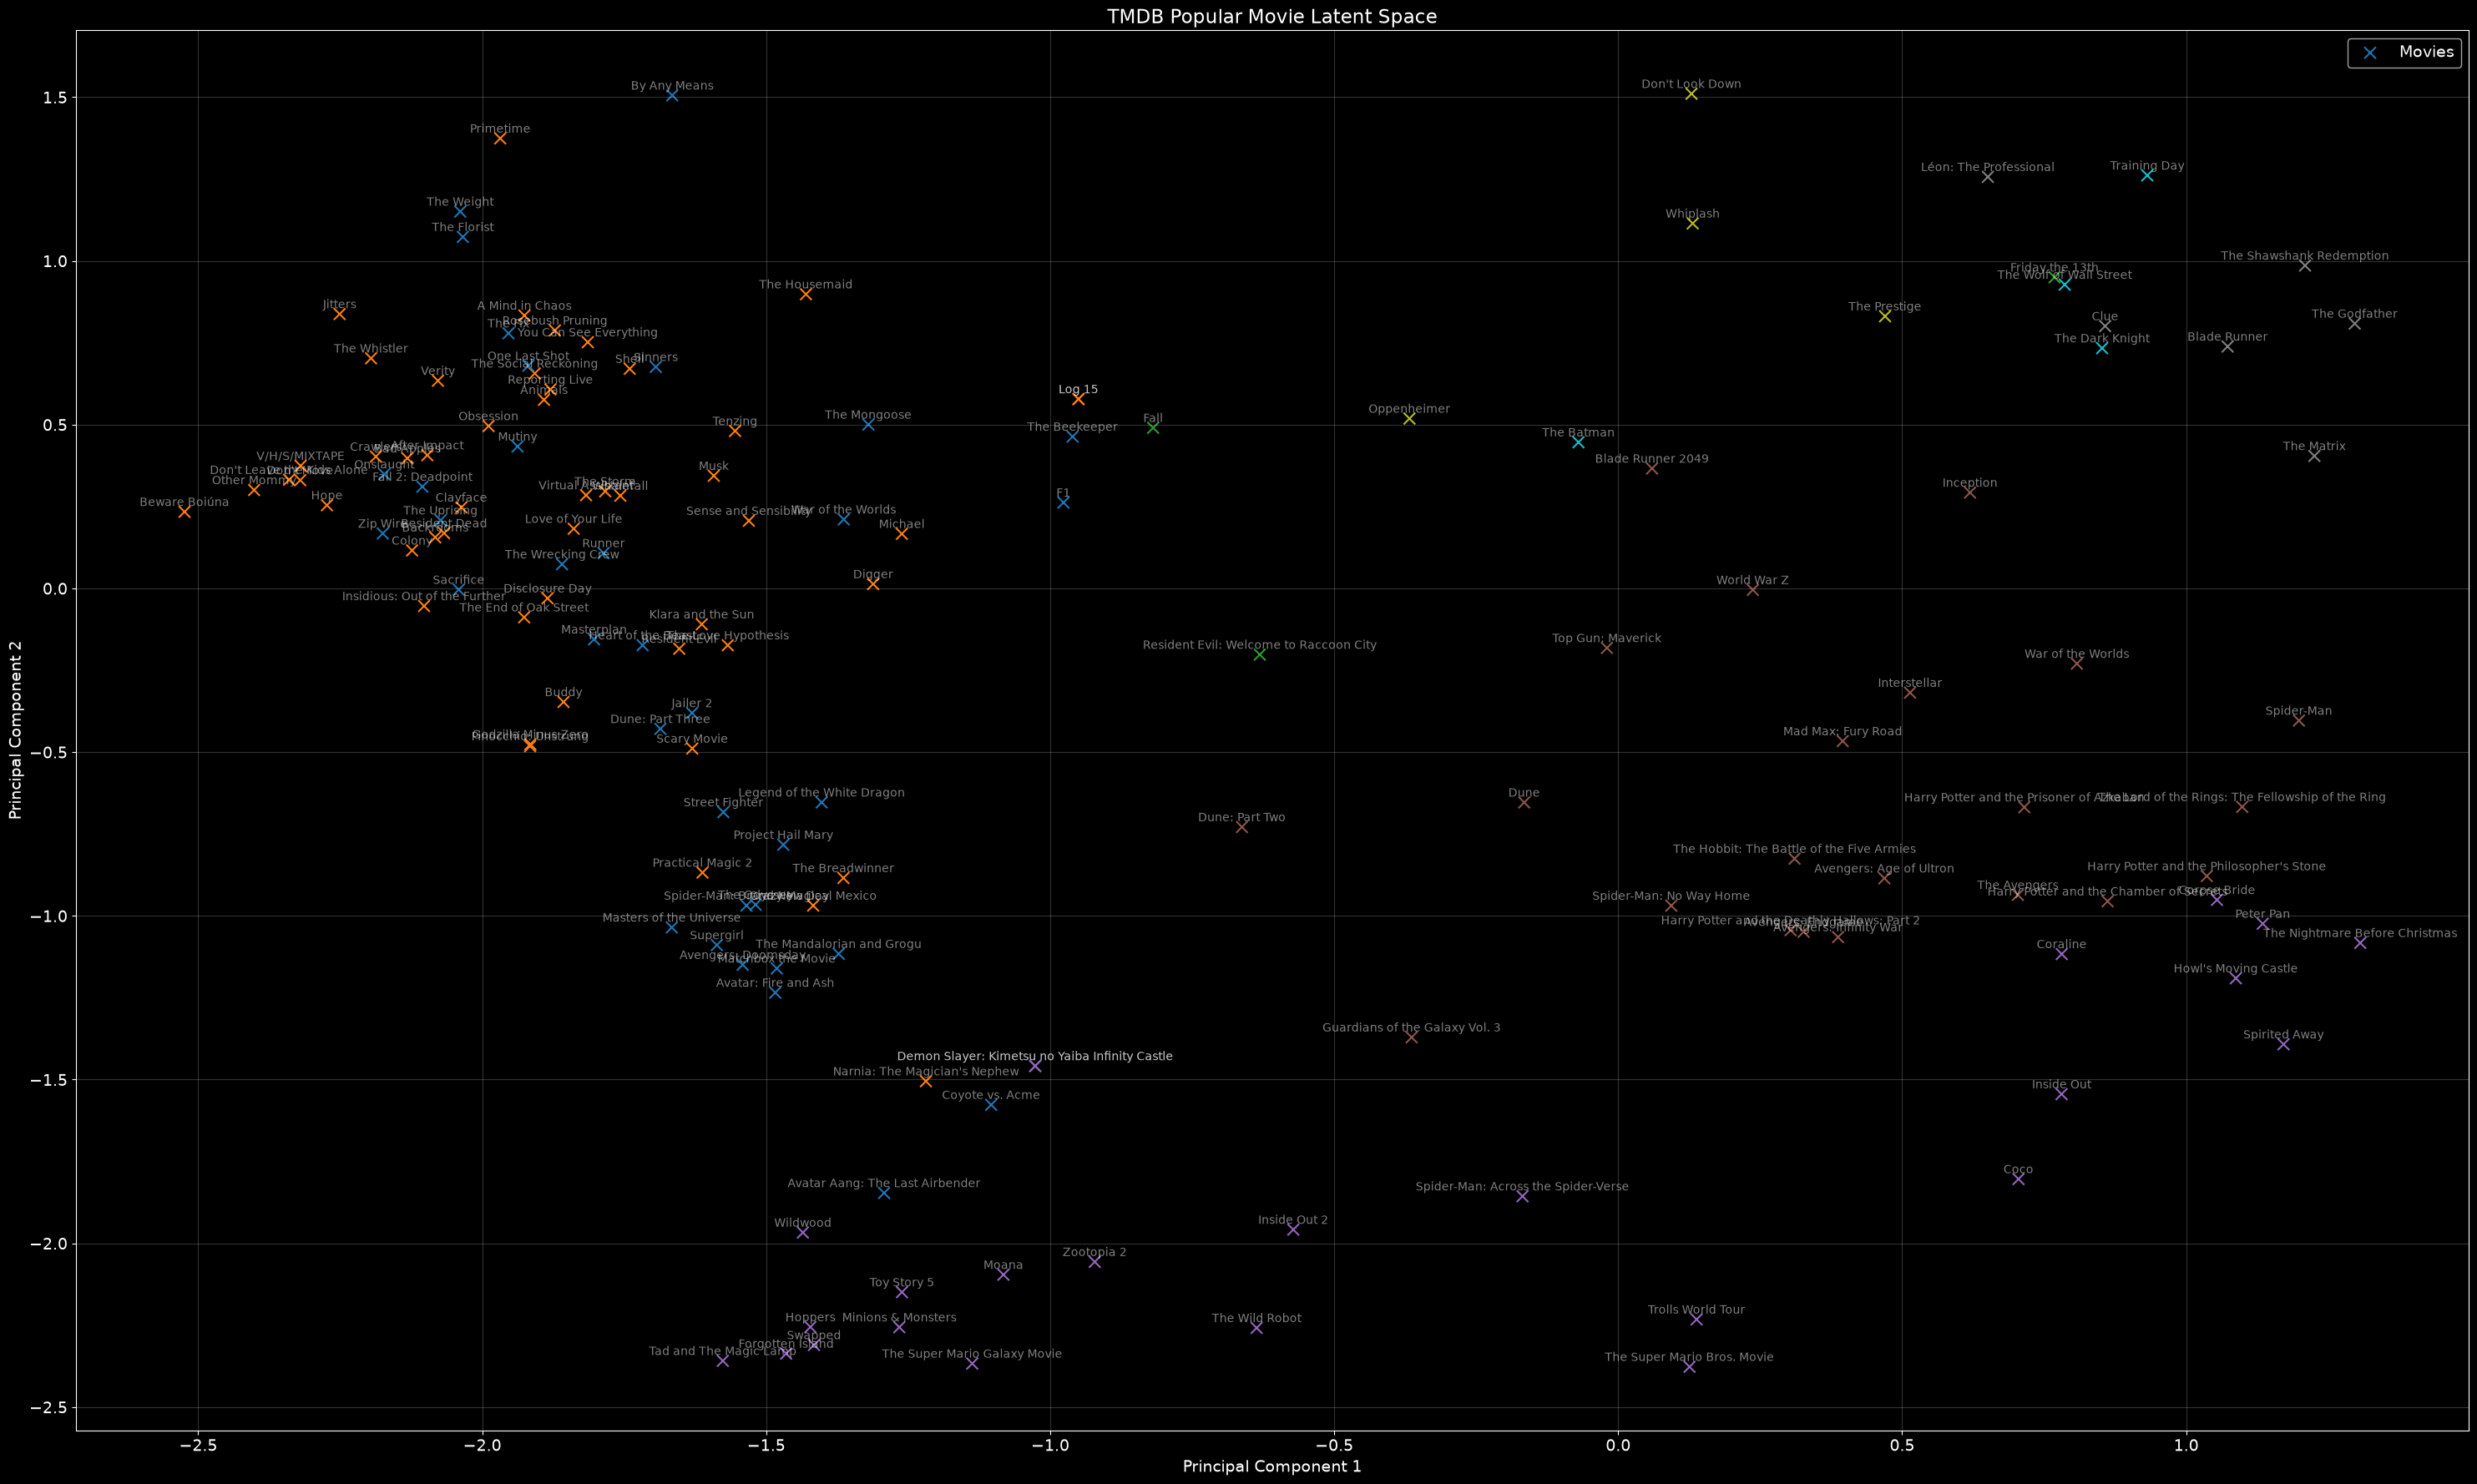

In [34]:
# clustering time
from sklearn.cluster import KMeans
n_clusters = 8

kmeans = KMeans(n_clusters=n_clusters, random_state=67, n_init="auto")
labels = kmeans.fit_predict(embeddings)

# scatter projected embeddings by clusters
plt.scatter(pc1, pc2, marker="x", label="Movies", cmap="tab10", c=labels[:n_plot], s=100)

# add movie titles
for x, y, title in zip(pc1, pc2, df.title.tolist()):
    plt.annotate(title, (x,y), textcoords="offset points", xytext=(0,5), ha="center", fontsize=10, alpha=0.5)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("TMDB Popular Movie Latent Space")
plt.legend()
plt.tight_layout()
plt.savefig("./src/imgs/popular-movie-latent-space-clusters.jpg")
plt.show()